# 03 · Article types

This notebook gives every article a type (battle, person, place, …) so the page can filter by it, and so the themes can be compared with something that doesn't come from links.

- Labels: I hand-labeled a random sample of 200 articles (`data/labels/labels.csv`) following the codebook in `data/labels/codebook.md`. The seed is left unlabeled. 50 more articles, the ones the model was least sure about, were labeled in an active-learning round (section 5). The `source` column in `labels.csv` records which labels came from where.
- Classifier: TF-IDF + logistic regression on each article's text only (title, short description, first paragraph), never its links. If the model used links, the predicted types would partly repeat the link structure and comparing them with the link-based themes would be circular. Text is also the more natural signal for type: text says what kind of thing an article is, links say what it's connected to.
- Evaluation: repeated stratified 5-fold cross-validation on the random 200. Since the sample is random, the score is an estimate of accuracy on the unlabeled articles. Macro-F1 is the main metric so that small categories count as much as large ones.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED = "Hundred Years' War"

articles = pd.read_parquet(ROOT / "data" / "processed" / "articles.parquet").set_index("title")
articles[["shortdesc", "first_paragraph"]] = articles[["shortdesc", "first_paragraph"]].fillna("")
label_table = pd.read_csv(ROOT / "data" / "labels" / "labels.csv").set_index("title")

random_sample = label_table["source"].fillna("").str.startswith("Amos")
labels = label_table["label"].where(random_sample)
labeled = labels.dropna()
all_labeled = label_table["label"].dropna()

def text(title):
    a = articles.loc[title]
    return " . ".join([title, a["shortdesc"], a["first_paragraph"]])

X = labeled.index.map(text).to_numpy()
y = labeled.to_numpy()
CATEGORIES = labeled.value_counts().index.tolist() 
print(f"{len(labeled)} in the random sample, {len(all_labeled)} labeled in all, of {len(labels) - 1} articles (seed excluded)")
print(label_table["source"].value_counts())
labeled.value_counts()

199 in the random sample, 249 labeled in all, of 788 articles (seed excluded)
source
Amos (random sample)                    199
Claude (round 1, uncertain articles)     50
Name: count, dtype: int64


label
historical people                    35
scholarship and media                30
battles and sieges                   29
periods, culture and religion        20
dynasties and polities               19
events and treaties                  15
wars and campaigns                   13
military concepts and technology     12
places                               12
institutions, titles and concepts     9
other                                 5
Name: count, dtype: int64

## 1. Cross-validation


In [2]:
def model():
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(max_iter=5000, class_weight="balanced"),
    )

REPEATS = 10
predictions = [cross_val_predict(model(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=r))
               for r in range(REPEATS)]
macro_f1 = [f1_score(y, p, average="macro") for p in predictions]
accuracy = [accuracy_score(y, p) for p in predictions]
majority = (y == labeled.value_counts().index[0]).mean()
print(f"macro-F1 {np.mean(macro_f1):.2f} ± {np.std(macro_f1):.2f} | accuracy {np.mean(accuracy):.2f} ± {np.std(accuracy):.2f} "
      f"| baseline (always the largest category) {majority:.2f}")

per_class = pd.DataFrame({
    "n": labeled.value_counts(),
    "F1": pd.DataFrame([f1_score(y, p, average=None, labels=CATEGORIES) for p in predictions], columns=CATEGORIES).mean(),
}).round(2).sort_values("F1")
per_class

macro-F1 0.67 ± 0.02 | accuracy 0.77 ± 0.01 | baseline (always the largest category) 0.18


,n,F1
other,5,0.00
wars and campaigns,13,0.55
events and treaties,15,0.56
"institutions, titles and concepts",9,0.59
"periods, culture and religion",20,0.70
military concepts and technology,12,0.75
dynasties and polities,19,0.76
scholarship and media,30,0.84
battles and sieges,29,0.85
places,12,0.86


## 2. Which categories get confused

The confusion matrix counts, across all repeats, how often an article from one category (row) was predicted as another (column), as a share of the row. A pair that gets confused in both directions and across repeats probably can't be separated from the text, and would be a candidate for merging.

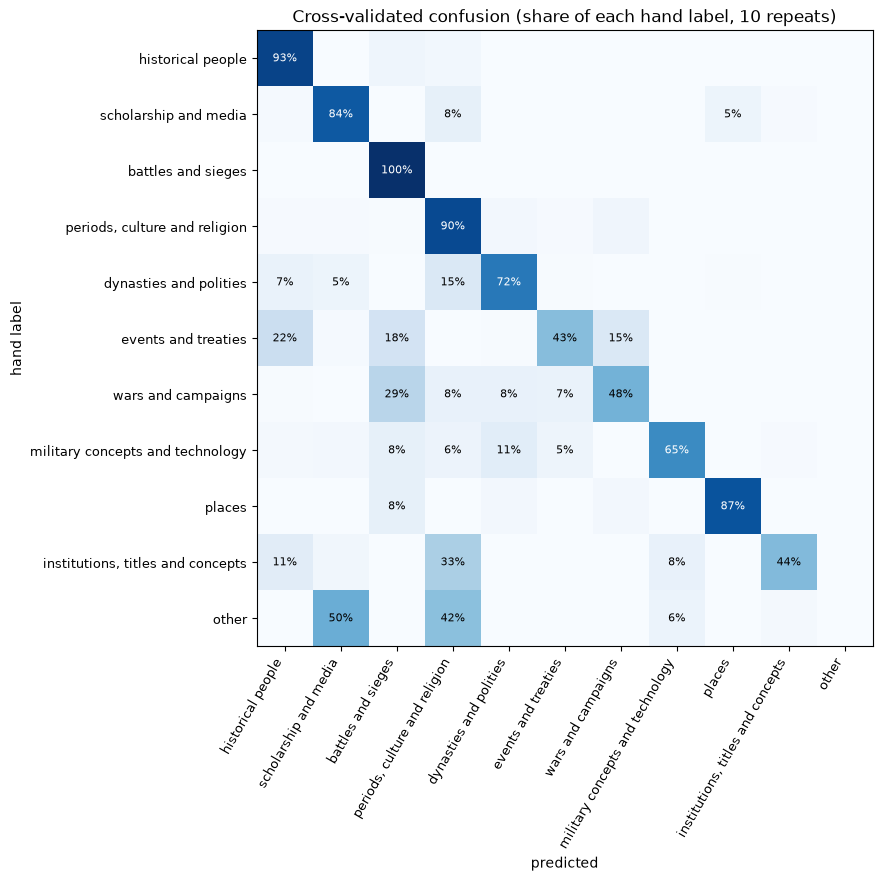

In [3]:
counts = sum(confusion_matrix(y, p, labels=CATEGORIES) for p in predictions)
shares = pd.DataFrame(counts / counts.sum(axis=1, keepdims=True), index=CATEGORIES, columns=CATEGORIES)

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CATEGORIES)), CATEGORIES, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(CATEGORIES)), CATEGORIES, fontsize=9)
for i in range(len(CATEGORIES)):
    for j in range(len(CATEGORIES)):
        if shares.iat[i, j] >= 0.05:
            ax.text(j, i, f"{shares.iat[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if shares.iat[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("hand label")
ax.set_title("Cross-validated confusion (share of each hand label, 10 repeats)");

In [4]:
# Pairs ranked by how often either one is mistaken for the other.
pairs = []
for i, a in enumerate(CATEGORIES):
    for j, b in enumerate(CATEGORIES):
        if i < j:
            pairs.append({"pair": f"{a} ↔ {b}", f"{'a → b'}": shares.iat[i, j], "b → a": shares.iat[j, i],
                          "mistakes per repeat": (counts[i, j] + counts[j, i]) / REPEATS})
pairs = pd.DataFrame(pairs).sort_values("mistakes per repeat", ascending=False)
pairs.head(8).round(2)

,pair,a → b,b → a,mistakes per repeat
22,battles and sieges ↔ wars and campaigns,0.00,0.29,3.8
27,"periods, culture and religion ↔ dynasties and ...",0.02,0.15,3.3
4,historical people ↔ events and treaties,0.00,0.22,3.3
40,events and treaties ↔ wars and campaigns,0.15,0.07,3.1
32,"periods, culture and religion ↔ institutions, ...",0.00,0.33,3.0
21,battles and sieges ↔ events and treaties,0.00,0.18,2.7
11,"scholarship and media ↔ periods, culture and r...",0.08,0.01,2.7
18,scholarship and media ↔ other,0.00,0.50,2.5


In [5]:
# The articles behind the mistakes: those misclassified in most repeats.
votes = pd.DataFrame(predictions, columns=labeled.index).T
wrong_share = (votes.ne(y, axis=0)).mean(axis=1)
most_predicted = votes.mode(axis=1)[0]
mistakes = pd.DataFrame({"hand label": y, "usually predicted": most_predicted, "wrong in": wrong_share},
                        index=labeled.index)
mistakes[mistakes["wrong in"] >= 0.5].sort_values(["hand label", "wrong in"], ascending=[True, False])

,hand label,usually predicted,wrong in
title,,,
Clan Carmichael,dynasties and polities,scholarship and media,1.0
Roman Empire,dynasties and polities,"periods, culture and religion",1.0
Angevin kings of England,dynasties and polities,historical people,1.0
History of the European Union,dynasties and polities,"periods, culture and religion",0.7
Spanish Empire,dynasties and polities,"periods, culture and religion",0.6
Canonization of Joan of Arc,events and treaties,historical people,1.0
English claims to the French throne,events and treaties,historical people,1.0
John of Gaunt's claims to the Castilian throne,events and treaties,historical people,1.0
Levant Crisis,events and treaties,wars and campaigns,1.0


## 3. What the model reads

The highest-weighted words for each category, from a model trained on all 200. They show whether the classifier is picking up sensible cues (a reign's years for people, "commune" for places) or quirks of the sample.

In [6]:
final = model().fit(X, y)
vectorizer, classifier = final.named_steps.values()
words = np.array(vectorizer.get_feature_names_out())
top = {c: ", ".join(words[np.argsort(classifier.coef_[k])[::-1][:8]]) for k, c in enumerate(classifier.classes_)}
pd.Series(top, name="top words").to_frame()

,top words
battles and sieges,"battle, battle of, siege, siege of, the battle..."
dynasties and polities,"house of, house, union, kingdom of, kingdom, d..."
events and treaties,"treaty, treaty of, incident, between, taxes, 1..."
historical people,"his, he, king, king of, he was, duke of, duke,..."
"institutions, titles and concepts","title, feudal, legal, medieval, in medieval, h..."
military concepts and technology,"or, person, piracy, tactical, individuals, hea..."
other,"ice, name of, bloody, of joan, name, hail, dys..."
"periods, culture and religion","period, antiquity, classical, middle, late, mi..."
places,"commune, commune in, city, region, department,..."
scholarship and media,"historian, university, film, academic, america..."


## 4. Would merging categories help?

Cross-validated scores with the confused pairs merged, with and without *other* as a predicted category. Without it, articles labeled *other* are left out and *other* is only assigned by hand.

In [7]:
def score(labels_used):
    keep = labels_used.notna().to_numpy()
    y_ = labels_used[keep].to_numpy()
    preds = [cross_val_predict(model(), X[keep], y_, cv=StratifiedKFold(5, shuffle=True, random_state=r)) for r in range(REPEATS)]
    return np.mean([f1_score(y_, p, average="macro") for p in preds]), np.mean([accuracy_score(y_, p) for p in preds]), len(set(y_))

WARS = {"battles and sieges": "battles and wars", "wars and campaigns": "battles and wars"}
CULTURE = {"institutions, titles and concepts": "institutions, culture and periods",
           "periods, culture and religion": "institutions, culture and periods"}
variants = {"as labeled": {}, "battles + wars": WARS, "institutions + periods": CULTURE, "both merges": {**WARS, **CULTURE}}
rows = []
for name, merge in variants.items():
    for other in ["predicted", "hand only"]:
        used = labeled.replace(merge)
        if other == "hand only":
            used = used.where(used != "other")
        f1, acc, k = score(used)
        rows.append({"merge": name, "other": other, "categories": k, "macro-F1": f1, "accuracy": acc})
pd.DataFrame(rows).round(2)

,merge,other,categories,macro-F1,accuracy
0,as labeled,predicted,11,0.67,0.77
1,as labeled,hand only,10,0.75,0.80
2,battles + wars,predicted,10,0.67,0.78
3,battles + wars,hand only,9,0.76,0.80
4,institutions + periods,predicted,10,0.68,0.78
5,institutions + periods,hand only,9,0.77,0.81
6,both merges,predicted,9,0.68,0.79
7,both merges,hand only,8,0.78,0.81


## Findings

- The classifier works reasonably well: macro-F1 0.67 and accuracy 0.77 (baseline 0.18), and it's stable across splits (± 0.02). People, places, battles and scholarship are easy (F1 0.84–0.88) because their short descriptions say what they are ("King of…", "commune in…", "historian").
- *Other* is never predicted (F1 0). Its five articles (hail, dysentery, a name) have nothing in common. Dropping it from the predicted categories gives the biggest gain (macro-F1 0.75), and it stays as a label I assign by hand.
- The confusions mostly go one way and come from specific articles rather than overlapping categories:
  - 29% of wars and campaigns get predicted as battles (campaigns and civil wars whose text is full of battles), never the other way around.
  - A third of institutions, titles and concepts go to periods, culture and religion (*Chivalry*, *Feudalism*, *Medieval university*).
  - Events and treaties is the most scattered category: claims to a throne look like people, incidents look like wars, and truces and revolts look like battles.
- Merging the confused pairs barely helps (at most +0.03 macro-F1), so I kept the categories. The distinctions matter for the analysis (a battle is an episode of the war, a war is context), and the confusions are better fixed by labeling more of exactly those cases.

## 5. Active learning, round 1

Instead of labeling more articles at random, label the ones the model is least sure about, since each of those teaches it the most. Uncertainty here is the margin between the probabilities of the model's first and second choice. A small margin means it's torn between two categories.

- The model is trained on all labels except *other*, which is only assigned by hand (section 4).
- The 50 articles with the smallest margins are written to `data/labels/to_label_round1.csv` with their short description, first paragraph and the model's top two guesses, then labeled with the codebook.
- The probabilities themselves are squeezed toward uniform (the top guess averages about 0.13 across 10 categories) because of the regularization. They aren't calibrated, so only their ranking is used.
- These 50 aren't a random sample, so the accuracy estimate is still based on the random 200 only.

In [8]:
BATCH = 50
train = labeled[labeled != "other"]
uncertain_model = model().fit(train.index.map(text).to_numpy(), train.to_numpy())

unlabeled = labels.index[labels.isna() & (labels.index != SEED)]
proba = uncertain_model.predict_proba(unlabeled.map(text).to_numpy())
order = np.argsort(-proba, axis=1)
classes = uncertain_model.classes_
first, second = proba[np.arange(len(proba)), order[:, 0]], proba[np.arange(len(proba)), order[:, 1]]

sheet = pd.DataFrame({
    "title": unlabeled,
    "shortdesc": articles.loc[unlabeled, "shortdesc"].to_numpy(),
    "first_paragraph": articles.loc[unlabeled, "first_paragraph"].str.slice(0, 300).to_numpy(),
    "guess_1": classes[order[:, 0]], "p_1": first.round(2),
    "guess_2": classes[order[:, 1]], "p_2": second.round(2),
    "margin": (first - second).round(3),
    "label": "",
}).sort_values("margin").head(BATCH)

out = ROOT / "data" / "labels" / "to_label_round1.csv"
if out.exists():
    print(f"{out.name} already exists: not overwritten (delete it to regenerate)")
else:
    sheet.drop(columns=["p_1", "p_2", "margin"]).to_csv(out, index=False)
    print(f"wrote {out.relative_to(ROOT)}: {len(sheet)} articles, margins {sheet.margin.min():.2f}–{sheet.margin.max():.2f}")
sheet.guess_1.value_counts()

to_label_round1.csv already exists: not overwritten (delete it to regenerate)


guess_1
periods, culture and religion        12
historical people                    10
scholarship and media                 8
dynasties and polities                6
wars and campaigns                    4
events and treaties                   3
battles and sieges                    3
institutions, titles and concepts     2
military concepts and technology      1
places                                1
Name: count, dtype: int64

## 6. Predict the rest

The final model is trained on all 249 labels (the random sample plus round 1), again without *other*, and predicts a type for the remaining articles. `data/processed/article_types.parquet` stores each article's type and whether it was labeled or predicted, so the page can mark predicted types.

In [9]:
train = all_labeled[all_labeled != "other"]
final_model = model().fit(train.index.map(text).to_numpy(), train.to_numpy())

titles = articles.index[articles.index != SEED]
types = pd.DataFrame({"title": titles, "type": all_labeled.reindex(titles).to_numpy()})
types["type_source"] = np.where(types["type"].notna(), "hand", "predicted")
missing = types["type"].isna()
types.loc[missing, "type"] = final_model.predict(types.loc[missing, "title"].map(text).to_numpy())

assert len(types) == 788 and types["type"].notna().all(), "one type per article, seed excluded"
types.to_parquet(ROOT / "data" / "processed" / "article_types.parquet", index=False)
types.drop(columns=[]).to_csv(ROOT / "data" / "processed" / "article_types.csv", index=False)
pd.crosstab(types["type"], types["type_source"], margins=True).sort_values("All", ascending=False)

type_source,hand,predicted,All
type,,,
All,249,539,788
battles and sieges,30,106,136
historical people,37,87,124
"periods, culture and religion",28,92,120
scholarship and media,36,79,115
dynasties and polities,20,60,80
wars and campaigns,27,42,69
places,13,35,48
events and treaties,21,14,35


## 7. Types vs themes, and closeness by type

The themes are the clusters from notebook 04 (that notebook runs after this one and uses these types to describe its clusters; the comparison here reads its saved output). The comparison only uses the random sample: predicted types would bring in classifier errors, and round 1 isn't random. Types say what kind of thing an article is, while themes say what it's connected to, so low agreement is expected and doesn't mean either one is wrong. A theme like the Edwardian phase should hold the battles, people and treaties of the same episode.

Closeness by type uses all 788 articles (labeled and predicted) as a description of the network.

In [10]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

clusters = pd.read_parquet(ROOT / "data" / "processed" / "clusters.parquet").set_index("title")
sample = labeled.to_frame("type").join(clusters["cluster_name"])
print(f"{len(sample)} hand-labeled articles (random sample) | "
      f"ARI {adjusted_rand_score(sample['type'], sample['cluster_name']):.2f} | "
      f"NMI {normalized_mutual_info_score(sample['type'], sample['cluster_name']):.2f}")
pd.crosstab(sample["cluster_name"], sample["type"])

199 hand-labeled articles (random sample) | ARI 0.25 | NMI 0.48


type,battles and sieges,dynasties and polities,events and treaties,historical people,"institutions, titles and concepts",military concepts and technology,other,"periods, culture and religion",places,scholarship and media,wars and campaigns
cluster_name,,,,,,,,,,,
Anglo-French conflicts beyond the war,1,0,5,0,0,0,0,2,0,0,8
Brittany and the Caroline phase,7,0,3,2,1,1,0,0,0,1,0
Burgundy and the Low Countries,2,0,0,2,1,0,0,0,1,0,1
Edwardian phase and cited scholarship,7,0,2,1,0,2,1,0,2,17,1
English monarchy,2,4,4,16,0,0,0,1,0,0,0
French monarchy and feudalism,0,3,0,7,5,0,1,0,0,1,0
Joan of Arc and her legacy,0,0,1,4,0,0,1,0,0,7,1
Lancastrian phase (1415–1453),10,0,0,3,0,0,0,0,0,0,0
Medieval society and culture,0,2,0,0,1,0,1,9,0,4,2


In [11]:
seed_similarity = pd.read_parquet(ROOT / "data" / "processed" / "seed_similarity.parquet").set_index("title")
by_type = types.set_index("title").join(seed_similarity["milne_witten_rank"])
(by_type.groupby("type")["milne_witten_rank"]
 .agg(articles="size", median_rank="median", closest="min")
 .sort_values("median_rank"))

,articles,median_rank,closest
type,,,
battles and sieges,136,223.0,5
"periods, culture and religion",120,277.5,18
dynasties and polities,80,369.0,12
historical people,124,397.5,1
wars and campaigns,69,424.0,3
events and treaties,35,480.0,21
other,8,483.5,129
"institutions, titles and concepts",26,585.0,36
scholarship and media,115,586.0,31


## Findings: types

- Every article now has a type: 249 labeled (199 random + 50 from round 1) and 539 predicted.
- Predicted shares drift from the random sample in the same direction as the confusions: battles 20% vs 15% (some campaigns and wars like *War of the Breton Succession* and *Gascon campaign of 1450–1453* end up as battles) and periods, culture and religion 17% vs 10% (abstract topics default there), while events (3% vs 8%), institutions and military concepts are under-predicted. Predicted types should be read as approximate, especially for those categories.
- Types and themes only partly agree on the random sample (ARI 0.25, NMI 0.48). Themes mix types by episode: the phase themes hold battles, treaties and people together, English monarchy is mostly people, and The Middle Ages in Europe is mostly polities.
- Closeness by type (median rank, all 788): battles 223, periods and culture 278, polities 369, people 398, wars 424, events 480, scholarship and media 586, places 649, military concepts 671. Battles are closest, since the war's article and its navboxes are built around them. Places are far even though the war was fought in them, because town and region articles link to everything in their history, not mainly to the war.